<a href="https://colab.research.google.com/github/Prateek-Dhar-Dwivedi/NLP_Practical_2026_Colab_Files/blob/main/Practical_04_SpamGuard_Dataset_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical 4: Building Datasets: Train/Test Split & Cross-Validation
## Project: SpamGuard — Text Dataset Evaluation Lab

**Module 2 · Intermediate Level · Google Colab**

### Learning objectives
- Load a labeled text-classification dataset.
- Split data into training and test sets correctly.
- Understand data leakage through preprocessing.
- Apply stratified sampling to preserve class proportions.
- Evaluate a text classifier with 5-fold stratified cross-validation.
- Compare accuracy, precision, recall, F1-score, and confusion matrices.

**Key rule:** Split first. Fit learned preprocessing only on the training data. During cross-validation, use a `Pipeline` so preprocessing is refit independently within each fold.

## 1. Install / import libraries

These libraries are commonly available in Google Colab. If needed, uncomment the installation line.

In [ ]:
# Uncomment only if your Colab environment needs these packages:
# %pip install -q pandas matplotlib seaborn scikit-learn

import io
import zipfile
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the SMS Spam Collection dataset

The notebook downloads the public SMS Spam Collection dataset from the UCI Machine Learning Repository. The dataset labels messages as `ham` (legitimate) or `spam`.

If downloading is blocked in your environment, upload the dataset file manually and adjust the loading cell.

In [ ]:
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

try:
    with urllib.request.urlopen(DATA_URL, timeout=30) as response:
        zip_bytes = response.read()

    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
        # The dataset file is usually named SMSSpamCollection (tab-separated, no header).
        candidates = [name for name in zf.namelist() if name.endswith("SMSSpamCollection")]
        if not candidates:
            raise FileNotFoundError("Could not find SMSSpamCollection in the downloaded ZIP.")
        with zf.open(candidates[0]) as file:
            df = pd.read_csv(
                file, sep="\t", header=None, names=["label", "message"],
                encoding="utf-8", on_bad_lines="skip"
            )
    print("Dataset downloaded successfully.")
except Exception as e:
    print("Automatic download failed:", repr(e))
    print("Upload the SMSSpamCollection file using the next cell.")
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No file uploaded.")
    uploaded_name = next(iter(uploaded))
    df = pd.read_csv(
        io.BytesIO(uploaded[uploaded_name]), sep="\t", header=None,
        names=["label", "message"], encoding="utf-8", on_bad_lines="skip"
    )

df = df.dropna(subset=["label", "message"]).copy()
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str)
df = df[df["label"].isin(["ham", "spam"])].reset_index(drop=True)

print(f"Rows: {len(df):,}")
display(df.head(10))

Dataset downloaded successfully.
Rows: 5,572


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


## 3. Explore the dataset and check data quality

Look at the labels, missing values, and duplicate messages before modeling. Duplicate rows are reported here rather than automatically removed, so you can see the original dataset structure.

In [ ]:
print("Dataset shape:", df.shape)
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))

print("\nClass counts:")
display(df["label"].value_counts().to_frame("message_count"))

print("\nExact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate message texts (regardless of label):", int(df["message"].duplicated().sum()))

display(df.sample(min(5, len(df)), random_state=RANDOM_STATE))

Dataset shape: (5572, 2)

Missing values:


,missing_count
label,0
message,0



Class counts:


,message_count
label,
ham,4825
spam,747



Exact duplicate rows: 403
Duplicate message texts (regardless of label): 403


,label,message
3245,ham,Squeeeeeze!! This is christmas hug.. If u lik ...
944,ham,And also I've sorta blown him off a couple tim...
1044,ham,Mmm thats better now i got a roast down me! i...
2484,ham,Mm have some kanji dont eat anything heavy ok
812,ham,So there's a ring that comes with the guys cos...


## 4. Visualize class imbalance

A class-imbalanced dataset contains different numbers of examples in each class. A model can appear accurate by predicting the majority class often, so accuracy should be interpreted alongside precision, recall, and F1-score.

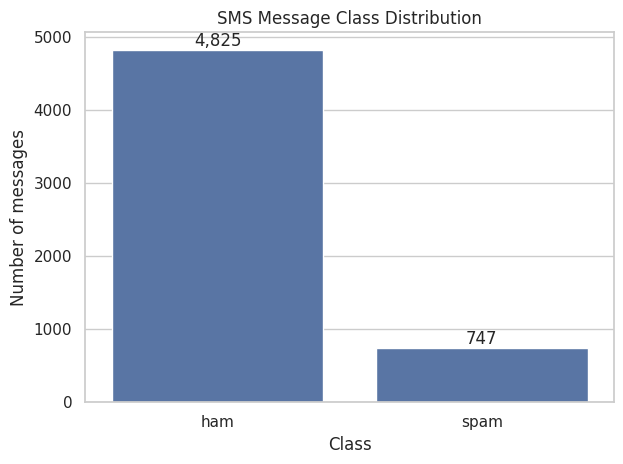

Class proportions:


,percentage
label,
ham,86.59
spam,13.41


In [ ]:
class_counts = df["label"].value_counts().reindex(["ham", "spam"], fill_value=0)
ax = sns.barplot(x=class_counts.index, y=class_counts.values)
ax.set_title("SMS Message Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of messages")
for i, value in enumerate(class_counts.values):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

print("Class proportions:")
display((df["label"].value_counts(normalize=True) * 100).round(2).rename("percentage").to_frame())

## 5. Create a stratified train/test split

We use an 80/20 split. `stratify=y` helps preserve the original ham/spam proportions in both sets.

We split the raw text before fitting TF-IDF. Do not fit a vectorizer on the full dataset before splitting.

In [ ]:
X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training messages: {len(X_train):,} ({len(X_train)/len(df):.1%})")
print(f"Testing messages:  {len(X_test):,} ({len(X_test)/len(df):.1%})")

split_distribution = pd.DataFrame({
    "Full dataset (%)": y.value_counts(normalize=True) * 100,
    "Training set (%)": y_train.value_counts(normalize=True) * 100,
    "Test set (%)": y_test.value_counts(normalize=True) * 100
}).fillna(0).round(2)
display(split_distribution)

Training messages: 4,457 (80.0%)
Testing messages:  1,115 (20.0%)


,Full dataset (%),Training set (%),Test set (%)
label,,,
ham,86.59,86.58,86.64
spam,13.41,13.42,13.36


## 6. Train a correct model with a Pipeline

The pipeline fits `TfidfVectorizer` on training messages only, then trains `MultinomialNB`. At test time, the already-fitted vectorizer transforms test messages without learning from them.

In [ ]:
model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Spam precision": precision_score(y_test, y_pred, pos_label="spam", zero_division=0),
    "Spam recall": recall_score(y_test, y_pred, pos_label="spam", zero_division=0),
    "Spam F1-score": f1_score(y_test, y_pred, pos_label="spam", zero_division=0),
}
display(pd.DataFrame.from_dict(metrics, orient="index", columns=["Test score"]).round(4))

print("\nClassification report:")
print(classification_report(y_test, y_pred, labels=["ham", "spam"], zero_division=0))

,Test score
Accuracy,0.9605
Spam precision,1.0000
Spam recall,0.7047
Spam F1-score,0.8268



Classification report:
              precision    recall  f1-score   support

         ham       0.96      1.00      0.98       966
        spam       1.00      0.70      0.83       149

    accuracy                           0.96      1115
   macro avg       0.98      0.85      0.90      1115
weighted avg       0.96      0.96      0.96      1115



## 7. Plot the confusion matrix

A confusion matrix shows correct and incorrect predictions for each class. For spam detection, false negatives are spam messages incorrectly classified as ham; false positives are legitimate messages incorrectly classified as spam.

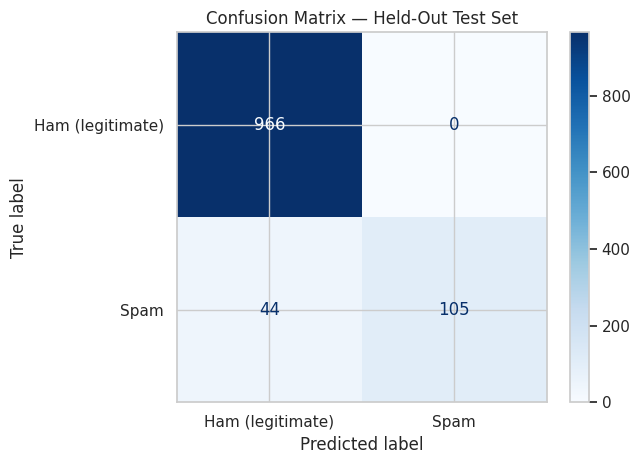

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=["ham", "spam"],
    display_labels=["Ham (legitimate)", "Spam"],
    cmap="Blues",
    values_format="d"
)
plt.title("Confusion Matrix — Held-Out Test Set")
plt.tight_layout()
plt.show()

## 8. Demonstrate preprocessing leakage

**Incorrect example:** fitting TF-IDF on all messages before splitting. This lets the test set influence the vocabulary and inverse-document-frequency statistics. It does not use test labels, and it may not noticeably increase the score, but it violates a clean evaluation protocol.

We compare the vocabulary and IDF statistics learned by a vectorizer fit on the full dataset against one fit only on training text. The scores are illustrative comparisons, not proof that leakage always improves accuracy.

In [ ]:
# Incorrect preprocessing: the vectorizer sees both training and test text.
leaky_vectorizer = TfidfVectorizer()
X_all_leaky = leaky_vectorizer.fit_transform(X)

# Correct preprocessing: fit only on training text.
correct_vectorizer = TfidfVectorizer()
X_train_correct = correct_vectorizer.fit_transform(X_train)
X_test_correct = correct_vectorizer.transform(X_test)

print("Vocabulary size when fit on ALL text (leaky):", len(leaky_vectorizer.vocabulary_))
print("Vocabulary size when fit on TRAIN text only:", len(correct_vectorizer.vocabulary_))
print("Test vocabulary terms learned only because full text was used:",
      len(set(leaky_vectorizer.vocabulary_) - set(correct_vectorizer.vocabulary_)))

# For a fairer demonstration, use the same classifier and split labels in both cases.
# This comparison is pedagogical: the leaky version has test-text-informed features.
leaky_clf = MultinomialNB()
leaky_clf.fit(X_all_leaky[X_train.index, :], y_train)
leaky_pred = leaky_clf.predict(X_all_leaky[X_test.index, :])

correct_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", MultinomialNB())
])
correct_pipeline.fit(X_train, y_train)
correct_pred = correct_pipeline.predict(X_test)

comparison = pd.DataFrame({
    "Approach": ["Leaky TF-IDF (fit on all messages)", "Correct Pipeline (fit on training only)"],
    "Accuracy": [
        accuracy_score(y_test, leaky_pred),
        accuracy_score(y_test, correct_pred)
    ],
    "Spam F1-score": [
        f1_score(y_test, leaky_pred, pos_label="spam", zero_division=0),
        f1_score(y_test, correct_pred, pos_label="spam", zero_division=0)
    ]
})
display(comparison.round(4))
print("Important: the leaky score may be similar or even lower. The problem is the evaluation protocol, not guaranteed score inflation.")

Vocabulary size when fit on ALL text (leaky): 8713
Vocabulary size when fit on TRAIN text only: 7668
Test vocabulary terms learned only because full text was used: 1045


,Approach,Accuracy,Spam F1-score
0,Leaky TF-IDF (fit on all messages),0.9605,0.8268
1,Correct Pipeline (fit on training only),0.9605,0.8268


Important: the leaky score may be similar or even lower. The problem is the evaluation protocol, not guaranteed score inflation.


## 9. Run 5-fold Stratified Cross-Validation

In 5-fold cross-validation, the training data is divided into five folds. Each fold is used once for validation while the other four folds train the model. Stratification helps preserve class proportions in each fold.

The pipeline is essential: in each fold, TF-IDF is fitted only on that fold's training portion. The held-out test set remains untouched during cross-validation.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision_weighted",
    "recall": "recall_weighted",
    "f1": "f1_weighted"
}

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

cv_table = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Weighted precision": cv_results["test_precision"],
    "Weighted recall": cv_results["test_recall"],
    "Weighted F1": cv_results["test_f1"]
})
display(cv_table.round(4))

summary = cv_table.drop(columns="Fold").agg(["mean", "std"]).T
summary.columns = ["Mean", "Standard deviation"]
display(summary.round(4))

,Fold,Accuracy,Weighted precision,Weighted recall,Weighted F1
0,1,0.9540,0.9564,0.9540,0.9499
1,2,0.9630,0.9645,0.9630,0.9604
2,3,0.9529,0.9553,0.9529,0.9484
3,4,0.9551,0.9573,0.9551,0.9511
4,5,0.9596,0.9614,0.9596,0.9565


,Mean,Standard deviation
Accuracy,0.9569,0.0043
Weighted precision,0.9590,0.0039
Weighted recall,0.9569,0.0043
Weighted F1,0.9533,0.0050


## 10. Compare cross-validation and final test performance

Cross-validation estimates how the model behaves across multiple training/validation splits. The held-out test score is the final evaluation on data not used for fitting or model selection.

In [ ]:
cv_mean_accuracy = cv_results["test_accuracy"].mean()
cv_std_accuracy = cv_results["test_accuracy"].std()
test_accuracy = accuracy_score(y_test, y_pred)

print(f"5-fold CV accuracy: {cv_mean_accuracy:.4f} ± {cv_std_accuracy:.4f} (standard deviation)")
print(f"Held-out test accuracy: {test_accuracy:.4f}")
print("\nInterpret results carefully: a small difference is normal; a large gap may suggest instability, distribution differences, or overfitting.")

5-fold CV accuracy: 0.9569 ± 0.0038 (standard deviation)
Held-out test accuracy: 0.9605

Interpret results carefully: a small difference is normal; a large gap may suggest instability, distribution differences, or overfitting.


## 11. Try the model on your own messages

Enter a sample SMS to see the predicted class. This is only a small demonstration, not a guarantee that every message will be classified correctly.

In [ ]:
examples = [
    "Congratulations! You have won a free prize. Call now to claim.",
    "Hey, are we still meeting at the library at 3 pm?",
    "URGENT! Your account has been selected for a reward. Click here."
]

example_predictions = model.predict(examples)
example_probabilities = model.predict_proba(examples)
spam_index = list(model.classes_).index("spam")

for message, prediction, probabilities in zip(examples, example_predictions, example_probabilities):
    print(f"Message: {message}")
    print(f"Prediction: {prediction.upper()} | Estimated spam probability: {probabilities[spam_index]:.1%}")
    print("-" * 80)

Message: Congratulations! You have won a free prize. Call now to claim.
Prediction: SPAM | Estimated spam probability: 87.9%
--------------------------------------------------------------------------------
Message: Hey, are we still meeting at the library at 3 pm?
Prediction: HAM | Estimated spam probability: 0.3%
--------------------------------------------------------------------------------
Message: URGENT! Your account has been selected for a reward. Click here.
Prediction: SPAM | Estimated spam probability: 50.5%
--------------------------------------------------------------------------------
